In [31]:
import pandas as pd

import matplotlib.pyplot as plt

df = pd.read_csv(
    "AirQualityUCI.csv",
    sep=";",
    decimal=","
)
df = df.dropna(axis = 1, how = "all")
df = df.dropna(axis = 0, how = 'all')

df

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9352,04/04/2005,10.00.00,3.1,1314.0,-200.0,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
9353,04/04/2005,11.00.00,2.4,1163.0,-200.0,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
9354,04/04/2005,12.00.00,2.4,1142.0,-200.0,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406
9355,04/04/2005,13.00.00,2.1,1003.0,-200.0,9.5,961.0,235.0,702.0,156.0,1041.0,770.0,28.3,13.5,0.5139


In [32]:
df.loc()

In [33]:
df = df[(df['CO(GT)'] >= 0) & (df['PT08.S1(CO)'] >= 0) & (df['NMHC(GT)']>= 0) & (df['C6H6(GT)'] >= 0) & (df['PT08.S2(NMHC)'] >= 0) & (df['NOx(GT)'] >= 0) & (df['PT08.S3(NOx)'] >= 0) & (df['NO2(GT)'] >= 0) & (df['PT08.S4(NO2)'] >= 0) & (df['PT08.S5(O3)'] >= 0) & (df['RH'] >= 0) & (df['AH'] >= 0)]

In [34]:
df.skew(numeric_only=True)

CO(GT)           1.066209
PT08.S1(CO)      0.565403
NMHC(GT)         1.485345
C6H6(GT)         0.998210
PT08.S2(NMHC)    0.351000
NOx(GT)          0.866116
PT08.S3(NOx)     0.832733
NO2(GT)          0.074280
PT08.S4(NO2)     0.691220
PT08.S5(O3)      0.337771
T                0.626299
RH               0.008160
AH               0.733666
dtype: float64

In [35]:
df["Hora"] = df["Time"].str.split(".").str[0].astype(int)

etiquetas = ["00-02", "03-05", "06-08", "09-11",
             "12-14", "15-17", "18-20", "21-23"]

df["Bloque"] = pd.cut(df["Hora"], bins=range(0, 25, 3), right=False, labels=etiquetas)

In [36]:
df.loc[df["Bloque"] == "00-02", "C6H6(GT)"].describe()

count    112.000000
mean       5.109821
std        3.007437
min        1.100000
25%        2.700000
50%        4.550000
75%        6.750000
max       15.200000
Name: C6H6(GT), dtype: float64

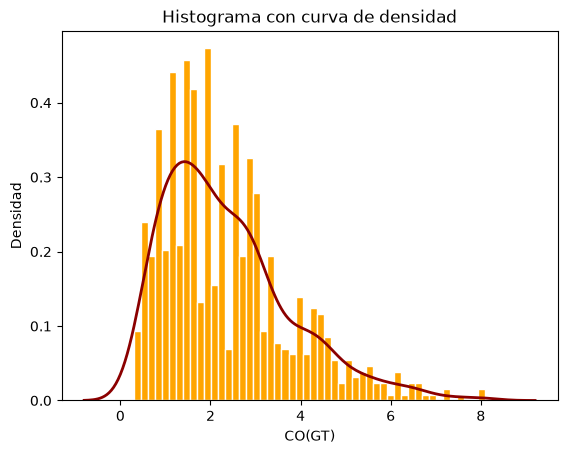

In [37]:
import seaborn as sns
datos = df['CO(GT)']
datos = datos[datos != -200].dropna()   # quita los faltantes

plt.figure()
plt.hist(datos, bins=50, color="orange", edgecolor="white", density=True)
sns.kdeplot(datos, color="darkred", linewidth=2)
plt.title('Histograma con curva de densidad')
plt.xlabel('CO(GT)')
plt.ylabel('Densidad')
plt.show()

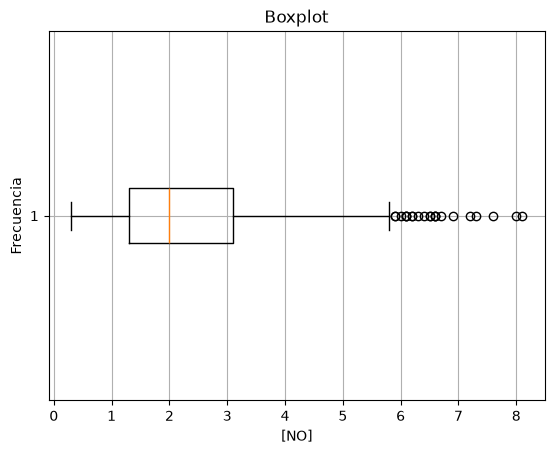

In [38]:
plt.figure()
plt.grid(True)
plt.boxplot(df['CO(GT)'], orientation='horizontal')
plt.title('Boxplot')
plt.xlabel('[NO]')
plt.ylabel('Frecuencia')
plt.show()

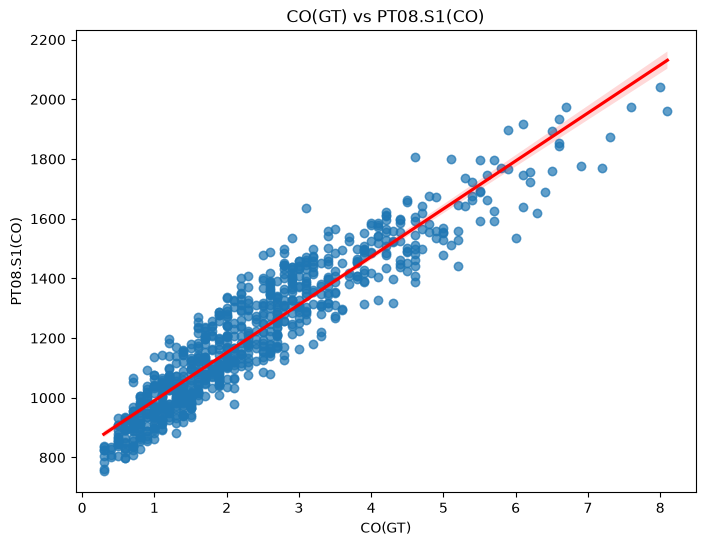

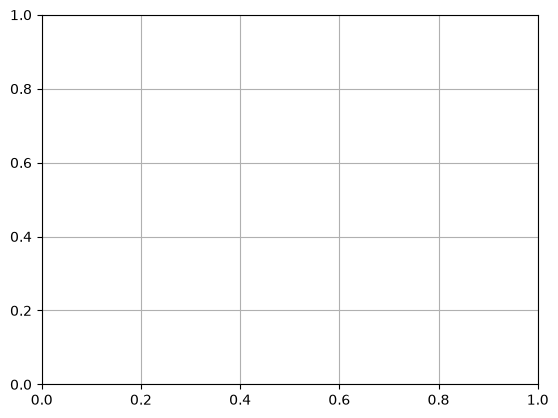

In [46]:
plt.figure(figsize=(8, 6))
plt.scatter(df['CO(GT)'], df['PT08.S1(CO)'], alpha=0.5)
plt.xlabel('CO(GT)')
plt.ylabel('PT08.S1(CO)')
plt.title('CO(GT) vs PT08.S1(CO)')

sns.regplot(data=df, x='CO(GT)', y='PT08.S1(CO)',
            scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
plt.title('CO(GT) vs PT08.S1(CO)')
plt.show()
plt.grid(True)
plt.show()
